In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
%matplotlib inline

In [2]:
df=pd.read_csv("/home/ubuntu/ds/LR/MLR/economic_index.csv")
df 

,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
0,0,2017,12,2.75,5.3,1464
1,1,2017,11,2.50,5.3,1394
2,2,2017,10,2.50,5.3,1357
3,3,2017,9,2.50,5.3,1293
4,4,2017,8,2.50,5.4,1256
5,5,2017,7,2.50,5.6,1254
6,6,2017,6,2.50,5.5,1234
7,7,2017,5,2.25,5.5,1195
8,8,2017,4,2.25,5.5,1159
9,9,2017,3,2.25,5.6,1167


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         24 non-null     int64  
 1   year               24 non-null     int64  
 2   month              24 non-null     int64  
 3   interest_rate      24 non-null     float64
 4   unemployment_rate  24 non-null     float64
 5   index_price        24 non-null     int64  
dtypes: float64(2), int64(4)
memory usage: 1.2 KB


In [4]:
type(df)

pandas.core.frame.DataFrame

In [5]:
df.drop(columns=["Unnamed: 0","year","month"],inplace=True)

In [6]:
df.head()

,interest_rate,unemployment_rate,index_price
0,2.75,5.3,1464
1,2.50,5.3,1394
2,2.50,5.3,1357
3,2.50,5.3,1293
4,2.50,5.4,1256


In [7]:
df.shape

(24, 3)

### the unnecessary columns have been removed , now lets check the null values and all 

In [8]:
df.isnull().sum()   

interest_rate        0
unemployment_rate    0
index_price          0
dtype: int64

### observed no null value is present 
### now lets check distribution and all 

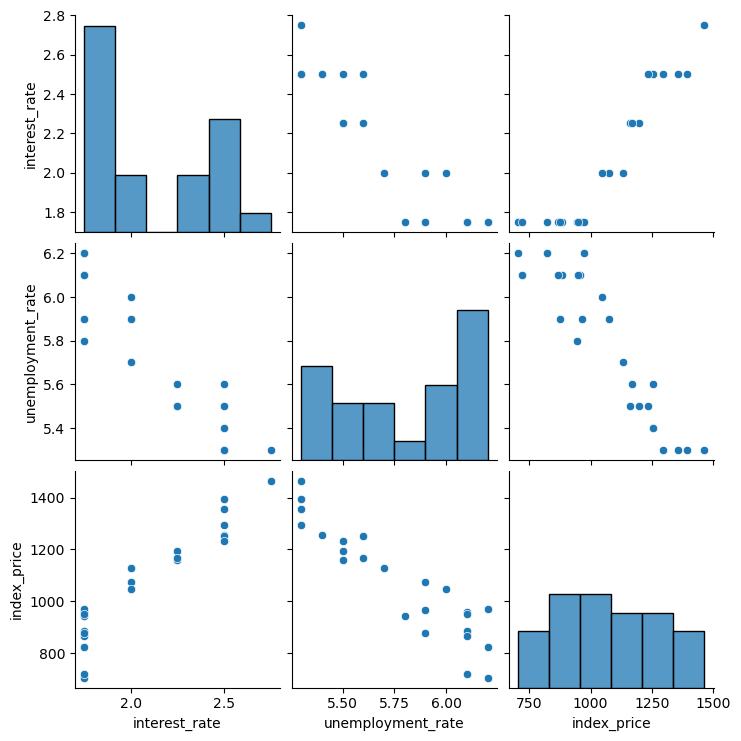

In [9]:
import seaborn as sns
sns.pairplot(df)

In [10]:
df.corr()

,interest_rate,unemployment_rate,index_price
interest_rate,1.000000,-0.925814,0.935793
unemployment_rate,-0.925814,1.000000,-0.922338
index_price,0.935793,-0.922338,1.000000


In [11]:
## seperate independent and dependent features 
df.head() 

,interest_rate,unemployment_rate,index_price
0,2.75,5.3,1464
1,2.50,5.3,1394
2,2.50,5.3,1357
3,2.50,5.3,1293
4,2.50,5.4,1256


In [12]:
## iloc is integer based indexing.. 
X=df.iloc[:,:-1] ## all rows , all columns except last one
y=df.iloc[:,-1]  ## all rows , only last column

In [13]:
X.head()

,interest_rate,unemployment_rate
0,2.75,5.3
1,2.50,5.3
2,2.50,5.3
3,2.50,5.3
4,2.50,5.4


In [14]:
y.head()

0    1464
1    1394
2    1357
3    1293
4    1256
Name: index_price, dtype: int64

In [15]:
type(X),type(y) ## as 2 cols were taken in X its automatically a 2d array

(pandas.core.frame.DataFrame, pandas.core.series.Series)

In [16]:
df.shape

(24, 3)

In [17]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

In [18]:
X_train.shape,y_train.shape,X_test.shape,y_test.shape

((18, 2), (18,), (6, 2), (6,))

<Axes: xlabel='interest_rate', ylabel='index_price'>

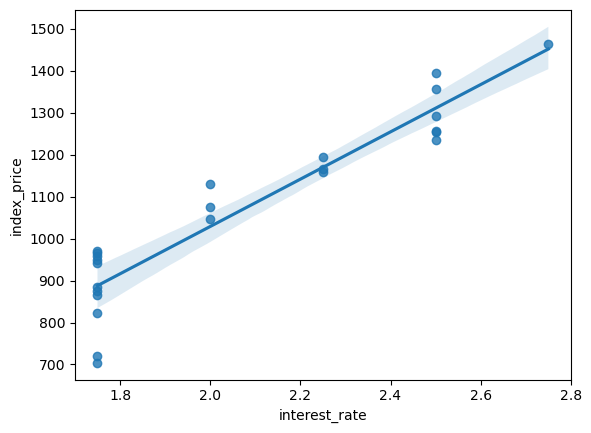

In [19]:
sns.regplot(x=df['interest_rate'],y=df['index_price'])

<Axes: xlabel='unemployment_rate', ylabel='index_price'>

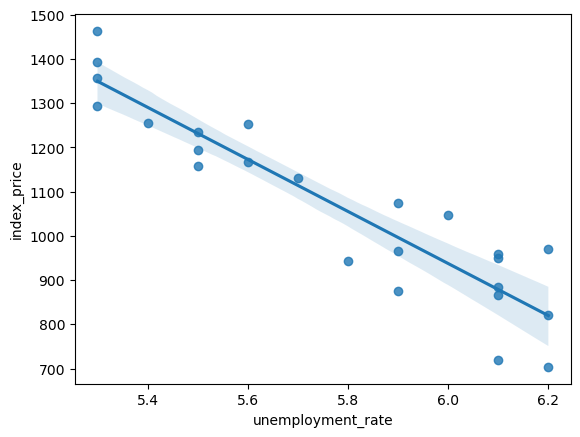

In [20]:
sns.regplot(x=df['unemployment_rate'],y=df['index_price'])

In [21]:
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()

In [22]:
X_train.head()

,interest_rate,unemployment_rate
13,1.75,5.9
1,2.50,5.3
21,1.75,6.2
5,2.50,5.6
2,2.50,5.3


In [23]:
X_test.head()

,interest_rate,unemployment_rate
8,2.25,5.5
16,1.75,6.2
0,2.75,5.3
18,1.75,6.1
11,2.00,5.9


In [24]:
X_train=ss.fit_transform(X_train)
X_test=ss.transform(X_test)

In [25]:
X_train

array([[-0.90115511,  0.37908503],
       [ 1.31077107, -1.48187786],
       [-0.90115511,  1.30956648],
       [ 1.31077107, -0.55139641],
       [ 1.31077107, -1.48187786],
       [-0.16384638,  0.68924552],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -1.48187786],
       [ 1.31077107, -1.17171738],
       [-0.90115511,  1.30956648],
       [-0.90115511,  0.999406  ],
       [-0.90115511,  0.37908503],
       [-0.90115511,  0.999406  ],
       [ 0.57346234, -0.8615569 ],
       [-0.16384638, -0.24123593],
       [-0.90115511,  0.06892455],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -0.8615569 ]])

In [26]:
X_test

array([[ 0.57346234, -0.8615569 ],
       [-0.90115511,  1.30956648],
       [ 2.0480798 , -1.48187786],
       [-0.90115511,  0.999406  ],
       [-0.16384638,  0.37908503],
       [ 0.57346234, -0.55139641]])

In [27]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()

In [28]:
lr.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [29]:
lr.coef_

array([  88.27275507, -116.25716066])

In [30]:
lr.intercept_

1053.4444444444443

### intercept found is one but the coefficients are two ... whays what about ??
### answer: well ofc --> h(theta)x= intercept + (theta)1x1 + (theta)2x2

In [34]:
lr.predict(X_train)

array([ 929.82565018, 1341.42873089,  821.65051903, 1233.25359973,
       1341.42873089,  958.85154593,  857.70889608, 1341.42873089,
       1305.37035383,  821.65051903,  857.70889608,  929.82565018,
        857.70889608, 1204.22770398, 1067.02667708,  965.88402724,
        857.70889608, 1269.31197678])

## cross validation 

In [36]:
from sklearn.model_selection import cross_val_score

In [38]:
val_score=cross_val_score(lr,X_train,y_train,scoring='neg_mean_squared_error',cv=6)

In [40]:
val_score

array([-2126.80466277, -5871.15675968, -8140.73503846, -9243.22230667,
       -9169.13776461,  -791.32842311])

In [41]:
np.mean(val_score)

-5890.397492548792

In [65]:
val_score.mean()

-5890.397492548792

In [43]:
lr.predict(X_test) ## this prediction is actually the y cap value ... ie the predicted y points 

array([1204.22770398,  821.65051903, 1406.51300368,  857.70889608,
        994.90992298, 1168.16932693])

In [45]:
y_pred=lr.predict(X_test)

## Perfomance Metrics
### In performnance metric we kind of compare the predicted values v/s the real to get a score. Aim is to minimise the error value ( basically getting a small value of error or the cost fucntion).
### question is why do we always do for test data ? and why not train ? 

#### compute metrics on the test set because it tells you how the model performs on unseen data. Doing it on the training set mostly tells you how well the model has memorized.
#### on the training data, you’re evaluating on the same data the model already saw.... That leads to:
#### 1. Optimistic results (looks better than reality)
#### 2. Risk of overfitting (model memorizes patterns, not generalizes)

In [49]:
from sklearn.metrics import r2_score

In [52]:
score=r2_score(y_test,y_pred)
score

0.8278978091457145

In [53]:
## adj_r2
print(1 - (1-score)*(len(y_test)-1)/(len(y_test)-X_test.shape[1]-1))

0.7131630152428576


In [ ]:
### now calculating the mse, mae, rmse

In [54]:
from sklearn.metrics import mean_squared_error,mean_absolute_error

In [58]:
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=np.sqrt(mse)
print(mse),print(mae),print(rmse)

5793.762887712569
59.935781523235484
76.11677139574805


(None, None, None)

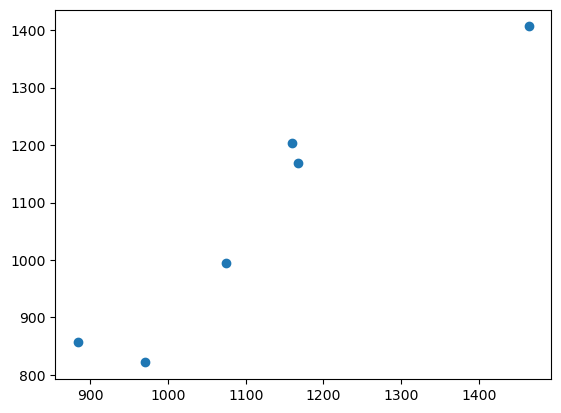

In [47]:
plt.scatter(y_test,y_pred)

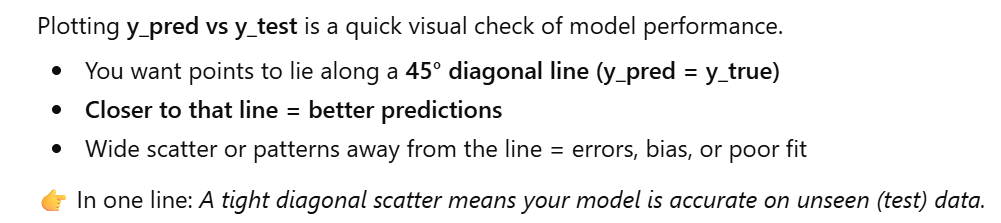
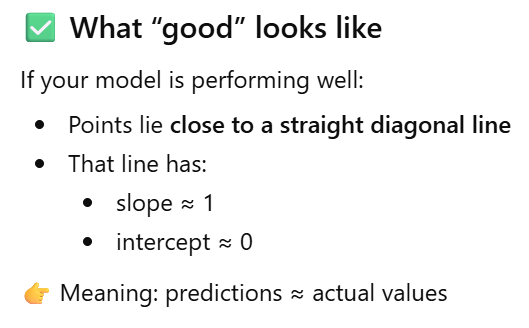

In [59]:
residuals=y_test-y_pred

In [60]:
residuals

8     -45.227704
16    149.349481
0      57.486996
18     26.291104
11     80.090077
9      -1.169327
Name: index_price, dtype: float64

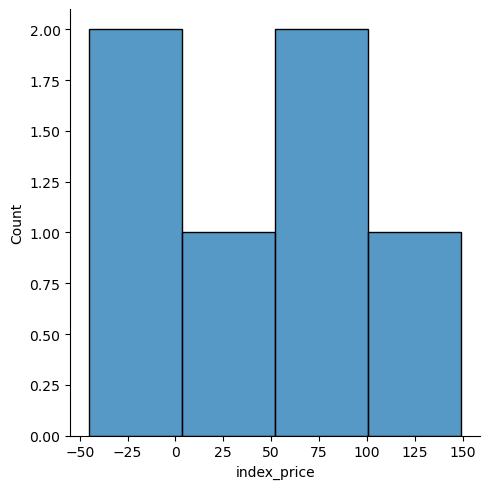

In [67]:
sns.displot(residuals,kind='hist')

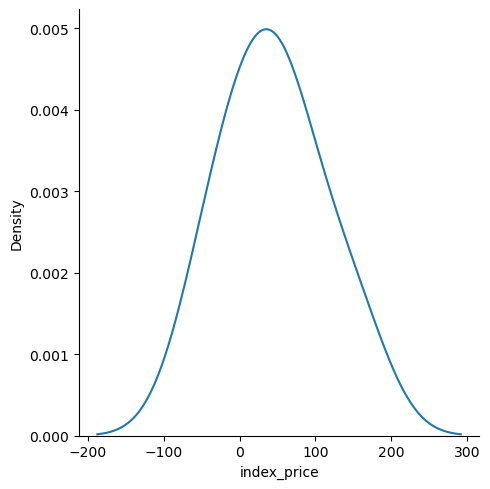

In [62]:
sns.displot(residuals,kind='kde')